In [3]:
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, Flatten, Dense, Reshape, Input
from tensorflow.keras.models import Model
from tensorflow.keras.losses import binary_crossentropy

# Загружаем набор данных MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(-1, 28, 28, 1) / 255.0  
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0  

print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1) (60000,) (10000,)


In [4]:
def sampling(args):
    z_mean, z_log =  args[0], args[1]
    epsilon = tf.keras.random.normal(shape=tf.shape(z_mean))
    return z_mean + tf.exp(0.5 * z_log) * epsilon # Сэмплирование

In [5]:
latent_dim = 2

inputs = layers.Input(shape=(28, 28, 1))
x = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
x = Conv2D(64, (3, 3), activation='relu', padding='same', strides=(2, 2))(x)
x = Conv2D(128, (3, 3), activation='relu', padding='same', strides=(2, 2))(x)
encoded = Flatten()(x)
x = Dense(64, activation='relu')(encoded)   
z_mean = Dense(latent_dim)(x)
z_log = Dense(latent_dim)(x)
    
z = layers.Lambda(sampling, output_shape=(latent_dim,))([z_mean, z_log])
encoder = Model(inputs, [z_mean, z_log, z], name="encoder")

latent_inputs = Input(shape=(latent_dim,))
x = Dense(7*7*64, activation='relu')(latent_inputs)
x = Reshape((7, 7, 64))(x)
x = Conv2DTranspose(64, (3, 3), activation='relu', padding='same', strides=(2, 2))(x)
x = Conv2DTranspose(32, (3, 3), activation='relu', padding='same', strides=(2, 2))(x)
decoded = Conv2DTranspose(1, (3, 3), activation='sigmoid', padding='same')(x)
decoder = models.Model(latent_inputs, decoded, name="decoder")

vae_outputs = decoder(encoder(inputs)[2]) 

vae = models.Model(inputs, vae_outputs, name="vae")
#vae.summary()
    
#reconstruction_loss = binary_crossentropy(K.flatten(inputs), K.flatten(decoded))
#reconstruction_loss *= 28 * 28
#kl_loss = -0.5 * K.sum(1 + z_log - tf.square(z_mean) - tf.exp(z_log), axis=-1)
#vae_loss = K.mean(reconstruction_loss + kl_loss)


vae.compile(optimizer='adam', loss='binary_crossentropy')

In [19]:
vae.fit(x_train, x_train, epochs=1, batch_size=128, validation_data=(x_test, x_test))

469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 87ms/step - loss: 0.1838 - val_loss: 0.1824


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━

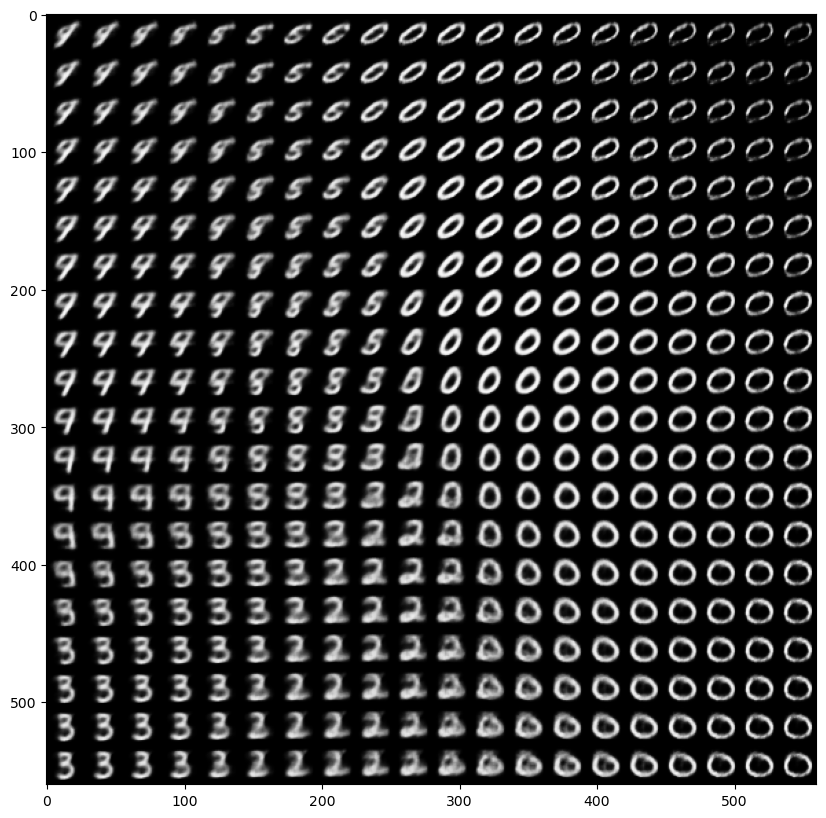

In [21]:
scale = 4.0
count = 20
digit_size = 28
def plot_latent_images(decoder):
    figure = np.zeros((28 * count, 28 * count))
    grid_x = np.linspace(-scale, scale, count)
    grid_y = np.linspace(-scale, scale, count)

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = np.array([[xi, yi]])
            x_decoded = decoder.predict(z_sample)
            digit = x_decoded[0].reshape(digit_size, digit_size)
            figure[i * digit_size: (i + 1) * digit_size,
                   j * digit_size: (j + 1) * digit_size] = digit

    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 10))
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

plot_latent_images(decoder)


In [2]:
z_mean, _, _ = encoder.predict(x_test)
plt.figure(figsize=(10, 10))
scatter = plt.scatter(z_mean[:, 0], z_mean[:, 1], c=y_test, cmap="tab10", s=5)
plt.colorbar(scatter)
plt.show()

NameError: name 'encoder' is not defined